## CUSTOMER CHURN PREDICTION 

In [1]:
# IMPORTING THE NECESSARY LIBRARIES 

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


## LOADING THE DATASET 

In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## UNDERSTANDING THE DATASET

In [4]:
# understanding the first five row of data from dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# checking the column in the dataset 
df.shape

(7043, 21)

In [6]:
# checking the summary statistics of dataset
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# information of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
# checking the null value in the dataset
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
# checking the num of customer left in the company and stayed in the company 
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
# checking the number of customer leving the company 
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 26.54%


In [11]:
#checking the percentage of customer churn
df["Churn"].value_counts(normalize = True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [12]:
# Visualizing the dataset

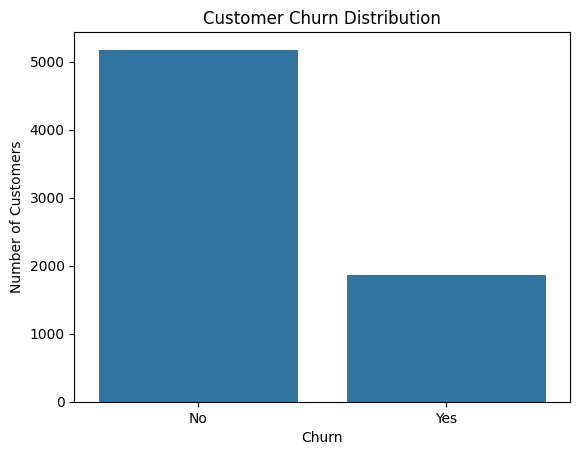

In [13]:
sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

## DATA CLEANING AND EXPLORATORY DATA ANALYSIS

In [14]:
# CHECKING THE DATA QUALITY OF DATASET
print("Rows and columns:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

print("Missing values:")
print(df.isnull().sum())

print("Data types:")
print(df.dtypes)

Rows and columns: (7043, 21)
Duplicate rows: 0
Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
Pa

In [15]:
# CHECKING THE CUSTOMER ID

In [16]:
print("Unique customers:", df["customerID"].nunique())

print("Total records:", len(df))

Unique customers: 7043
Total records: 7043


In [17]:
#CHECKING THE TOTAL CHARGES
print(df["TotalCharges"].dtype)

print(
    df["TotalCharges"].head(10)
)

object
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object


In [18]:
#CLEANING THE TOTAL_CHARGES IN THE DATASET

In [19]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtype)

print(
    "Missing TotalCharges:",
    df["TotalCharges"].isnull().sum()
)

float64
Missing TotalCharges: 11


In [20]:
# CHECKING THE MISSING VALUE

In [21]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [22]:
# CHECKING THE PERCENTAGE OF MISSING VALUE
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

customerID          0.000000
gender              0.000000
SeniorCitizen       0.000000
Partner             0.000000
Dependents          0.000000
tenure              0.000000
PhoneService        0.000000
MultipleLines       0.000000
InternetService     0.000000
OnlineSecurity      0.000000
OnlineBackup        0.000000
DeviceProtection    0.000000
TechSupport         0.000000
StreamingTV         0.000000
StreamingMovies     0.000000
Contract            0.000000
PaperlessBilling    0.000000
PaymentMethod       0.000000
MonthlyCharges      0.000000
TotalCharges        0.156183
Churn               0.000000
dtype: float64


In [23]:
df.loc[
    df["TotalCharges"].isnull(),
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [24]:
# CHECKING THE TOTAL CHARGES, MONTHLY CHARGES, TENURE OF THE GIVEN DATASET

In [25]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].head(10)

,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65
5,8,99.65,820.50
6,22,89.10,1949.40
7,10,29.75,301.90
8,28,104.80,3046.05
9,62,56.15,3487.95


In [26]:
# FILL THE MISSING THE VALUE IN TOTAL CHARGES
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print(
    "Remaining missing values:",
    df.isnull().sum().sum()
)

Remaining missing values: 0


In [27]:
# HANDLE THE DUPLICATE RECORD IN THE DATASET
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [28]:
# Analysis the data based on the customerid
print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Duplicate customer IDs: 0


## calculate the customer churn percentage 

### Business Analysis on customer churn dataset

In [29]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


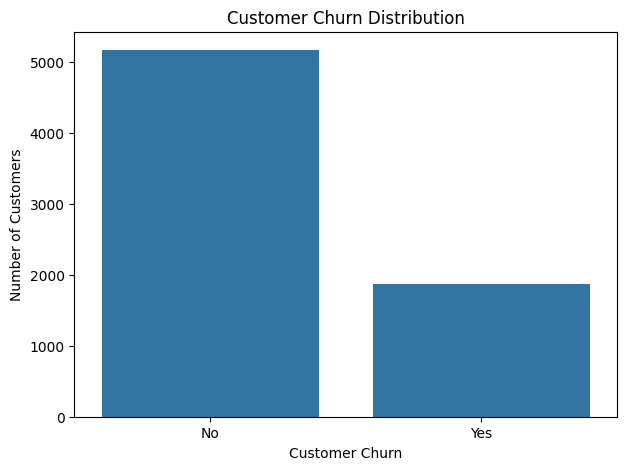

In [30]:
# visualizing the dataset
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [31]:
# Churn Rate By Contracte Rate
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


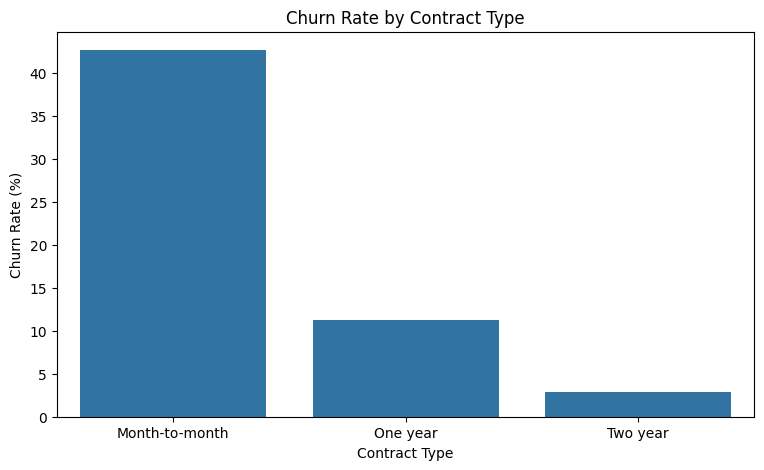

In [32]:
#visualizing the dataset by using graph
plt.figure(figsize=(9, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

# Customer Rate by Tenure

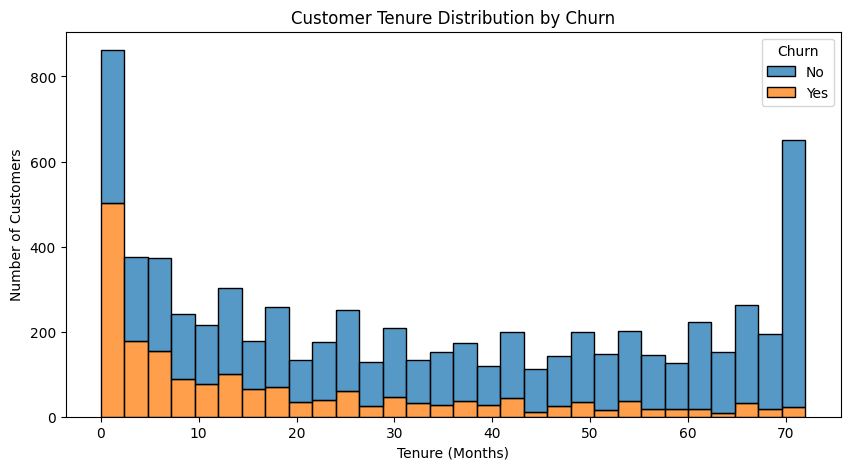

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [34]:
# Dividing the tenure in group 
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

In [35]:
#Group-wise churn:
tenure_churn = (
    df.groupby(
        "TenureGroup",
        observed=False
    )["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print(tenure_churn)

TenureGroup
0-12 months     47.438243
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: Churn, dtype: float64


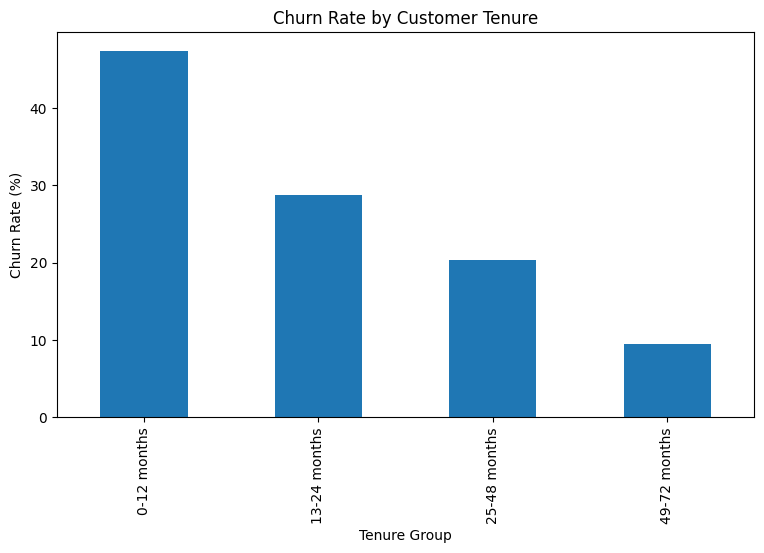

In [36]:
tenure_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

## Monthly charges vs churn

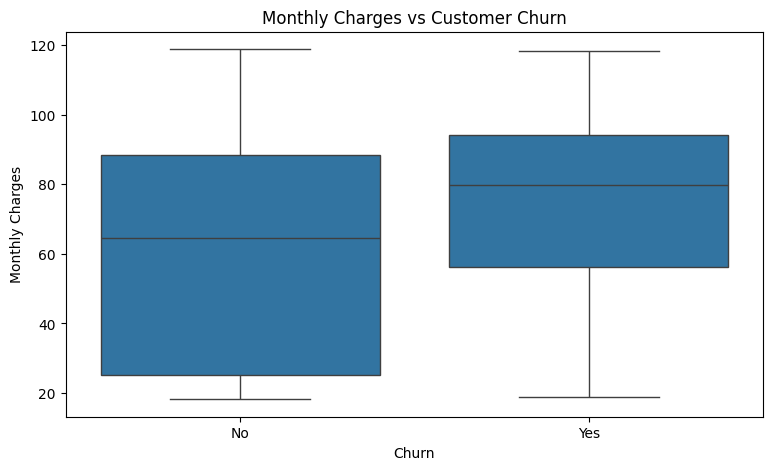

In [37]:
# checking the difference  in customer churned and customer retained in monthly charges
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [38]:
# Average monthly charges
monthly_charge_analysis = (
    df.groupby("Churn")["MonthlyCharges"]
    .mean()
)

print(monthly_charge_analysis)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [39]:
# Median monthly charges
print(
    df.groupby("Churn")["MonthlyCharges"].median()
)

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


## ANALYSIS THE CATEGORICAL FEATURE IN CUSTOMER CHURN DATASET

In [40]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [45]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost training complete.")

NameError: name 'y_train' is not defined